# Machine Learning Assignment 2 - Resubmission

**Dataset**:       Fitness


## Imports

Add imports here as needed.

Remember to **re-run the cell when you add imports**, so it gets loaded into the virtual notebook environment!

In [1]:
# Data and Datasets
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Clustering
from sklearn.cluster import DBSCAN

# Validation methods
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold

# Metrics
from sklearn import metrics
from sklearn.metrics import make_scorer
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier

# Hyper-parameter optimisation
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

# Feature selection & feature engineering
from sklearn.feature_selection import RFE
from sklearn.feature_selection import RFECV
from sklearn.decomposition import PCA

# Stats
from scipy.stats import randint as sp_randint
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import shapiro
from scipy.stats import normaltest
from scipy.stats import anderson
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import SVG
from IPython.display import display
from sklearn.tree import export_graphviz

# Utils
import pprint
import numpy as np
from time import time
import openpyxl
import random


## Loading the dataset

In [2]:
import pandas as pd

df = pd.read_csv("fitness_dataset.csv")

# printing out dataset info
print(df.info())
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Height             1598 non-null   float64
 1   Age                1601 non-null   float64
 2   Gender             1598 non-null   object 
 3   Smoker             1600 non-null   object 
 4   Activity Index     794 non-null    float64
 5   Sleep Hours        1467 non-null   float64
 6   Heart Rate         1476 non-null   float64
 7   Nutrition Quality  1601 non-null   float64
 8   Blood Pressure     1441 non-null   float64
 9   Weight             1600 non-null   float64
 10  Fitness Level      1610 non-null   object 
dtypes: float64(8), object(3)
memory usage: 138.5+ KB
None


,Height,Age,Gender,Smoker,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight,Fitness Level
0,152.0,56.0,Female,No,3.97,NaN,69.6,2.37,117.0,65.0,High
1,186.0,69.0,Female,No,3.19,7.5,60.8,8.77,114.8,95.0,High
2,192.0,46.0,Female,No,2.03,NaN,61.4,8.20,116.4,103.0,Low
3,189.0,32.0,Male,No,NaN,7.0,60.2,6.18,130.1,83.0,High
4,175.0,60.0,Female,Yes,NaN,8.0,58.1,9.95,115.8,99.0,High


In [3]:
df.describe()


,Height,Age,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight
count,1598.000000,1601.000000,794.000000,1467.000000,1476.000000,1601.000000,1441.000000,1600.000000
mean,174.080100,50.531543,2.875982,7.431152,70.233469,4.846471,118.836572,84.207500
std,14.380676,17.870658,1.127762,1.499842,11.848808,2.851291,18.142572,26.162062
min,150.000000,18.000000,1.000000,4.000000,45.000000,0.000000,0.000000,30.000000
25%,162.000000,36.000000,1.910000,6.400000,62.375000,2.420000,109.200000,64.000000
50%,173.000000,51.000000,2.780000,7.400000,70.100000,4.730000,119.800000,84.000000
75%,186.000000,66.000000,3.780000,8.500000,78.300000,7.210000,130.000000,103.000000
max,199.000000,79.000000,4.990000,12.000000,118.600000,10.000000,168.100000,250.000000


## Data Processing

### Data Quality

**Justification for data processing (linked to Assignment 1 EDA)**

Each cleaning step below follows a finding from the exploratory analysis, then an action, then why that action was chosen.

1. **Near-empty ("ghost") rows and duplicates**
   - **Specification:** rows that are mostly blank, plus exact duplicate records.
   - **Action:** drop them.
   - **Justification:** the EDA treated these as collection artefacts, not real people. Keeping them would inflate sample size without adding signal and can leak duplicated rows across train and test.

2. **Blood Pressure equal to 0**
   - **Specification:** clinically impossible resting BP values of 0.
   - **Action:** recode as missing, then impute with the rest of the numeric columns.
   - **Justification:** zero BP is domain-implausible noise. Treating it as missing is safer than leaving a hard zero that would distort scaled models.

3. **Extreme Weight values**
   - **Specification:** weights below 35 kg or above 150 kg (repeated extreme spikes seen in EDA).
   - **Action:** recode those values as missing rather than deleting the whole row.
   - **Justification:** other columns on those rows can still be useful. Clipping or blanking the noisy measurement preserves sample size while removing mathematical distortion.

4. **Activity Index (~51% missing)**
   - **Specification:** strongest correlate with fitness in EDA, but about half the values are missing.
   - **Action:** add `Activity_Index_was_missing`, then median-impute the column.
   - **Justification:** dropping the column removes a key predictor; dropping the rows halves the dataset. Median imputation fits the skewed numeric distributions found earlier. The missingness flag lets models use "was missing" as a signal in its own right.

5. **Remaining missing values**
   - **Specification:** leftover gaps in Height, Age, Sleep Hours, Heart Rate, Nutrition Quality, Blood Pressure, Weight, Gender, Smoker.
   - **Action:** median for numerics, mode for categoricals.
   - **Justification:** EDA showed skewed numerics, so the median is more robust than the mean; mode is the natural fill for binary categoricals.


In [4]:
df_clean = df.copy()
print(f"Starting shape: {df_clean.shape}")

# Drop near-empty ("ghost") rows: mostly blank across columns
ghost_threshold = int(0.8 * len(df_clean.columns))
before_ghost = len(df_clean)
df_clean = df_clean[df_clean.isnull().sum(axis=1) < ghost_threshold]
print(f"Dropped {before_ghost - len(df_clean)} near-empty row(s). Shape now: {df_clean.shape}")


Starting shape: (1610, 11)
Dropped 11 near-empty row(s). Shape now: (1599, 11)


In [5]:
bp_zero_count = (df_clean['Blood Pressure'] == 0).sum()
df_clean.loc[df_clean['Blood Pressure'] == 0, 'Blood Pressure'] = pd.NA
df_clean['Blood Pressure'] = pd.to_numeric(df_clean['Blood Pressure'])
print(f"Recoded {bp_zero_count} Blood Pressure values (0 -> NaN)")


Recoded 12 Blood Pressure values (0 -> NaN)


In [6]:
weight_noise_mask = (df_clean['Weight'] < 35) | (df_clean['Weight'] > 150)
weight_noise_count = weight_noise_mask.sum()
df_clean.loc[weight_noise_mask, 'Weight'] = pd.NA
df_clean['Weight'] = pd.to_numeric(df_clean['Weight'])
print(f"Recoded {weight_noise_count} extreme Weight values (>150 or <35) -> NaN")


Recoded 22 extreme Weight values (>150 or <35) -> NaN


In [7]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Dropped {before - len(df_clean)} duplicate row(s). New shape: {df_clean.shape}")


Dropped 0 duplicate row(s). New shape: (1599, 11)


In [8]:
df_clean['Activity_Index_was_missing'] = df_clean['Activity Index'].isna()
activity_median = df_clean['Activity Index'].median()
df_clean['Activity Index'] = df_clean['Activity Index'].fillna(activity_median)
print(f"Activity Index imputed with median = {activity_median}")
print(f"Flag column added: {df_clean['Activity_Index_was_missing'].sum()} rows flagged as originally missing")


Activity Index imputed with median = 2.78
Flag column added: 807 rows flagged as originally missing


**5. Remaining missing values: impute the rest**

For the remaining numeric columns we use median imputation (robust to the outliers/skew found earlier). For the categorical columns (Gender, Smoker) we use the mode.


In [9]:
numeric_to_impute = ['Height', 'Age', 'Sleep Hours', 'Heart Rate', 'Nutrition Quality', 'Blood Pressure', 'Weight']
categorical_to_impute = ['Gender', 'Smoker']

for col in numeric_to_impute:
    median_val = df_clean[col].median()
    n_missing = df_clean[col].isna().sum()
    df_clean[col] = df_clean[col].fillna(median_val)
    if n_missing > 0:
        print(f"{col}: imputed {n_missing} missing value(s) with median = {median_val}")

for col in categorical_to_impute:
    mode_val = df_clean[col].mode()[0]
    n_missing = df_clean[col].isna().sum()
    df_clean[col] = df_clean[col].fillna(mode_val)
    if n_missing > 0:
        print(f"{col}: imputed {n_missing} missing value(s) with mode = '{mode_val}'")


Height: imputed 1 missing value(s) with median = 173.0
Sleep Hours: imputed 133 missing value(s) with median = 7.4
Heart Rate: imputed 124 missing value(s) with median = 70.1
Blood Pressure: imputed 171 missing value(s) with median = 119.9
Weight: imputed 22 missing value(s) with median = 83.0
Gender: imputed 1 missing value(s) with mode = 'Female'


In [10]:
# Final check: confirm no missing values remain
print("Remaining missing values per column:")
print(df_clean.isna().sum())
print(f"\nFinal cleaned shape: {df_clean.shape}")


Remaining missing values per column:
Height                        0
Age                           0
Gender                        0
Smoker                        0
Activity Index                0
Sleep Hours                   0
Heart Rate                    0
Nutrition Quality             0
Blood Pressure                0
Weight                        0
Fitness Level                 0
Activity_Index_was_missing    0
dtype: int64

Final cleaned shape: (1599, 12)


In [11]:
print(f"Shape before cleaning: {df.shape}")
print(f"Shape after cleaning:  {df_clean.shape}")
print(f"\nMissing values remaining:\n{df_clean.isna().sum().sum()} total")
print()
df_clean.describe().T


Shape before cleaning: (1610, 11)
Shape after cleaning:  (1599, 12)

Missing values remaining:
0 total



,count,mean,std,min,25%,50%,75%,max
Height,1599.0,174.079425,14.376201,150.0,162.00,173.00,186.000,199.00
Age,1599.0,50.537836,17.864766,18.0,36.00,51.00,66.000,79.00
Activity Index,1599.0,2.827523,0.795367,1.0,2.78,2.78,2.780,4.99
Sleep Hours,1599.0,7.429081,1.436438,4.0,6.55,7.40,8.300,12.00
Heart Rate,1599.0,70.229268,11.381072,45.0,63.10,70.10,77.500,118.60
Nutrition Quality,1599.0,4.848630,2.852385,0.0,2.42,4.77,7.225,10.00
Blood Pressure,1599.0,119.843527,13.771824,90.0,110.75,119.90,128.800,168.10
Weight,1599.0,82.838024,21.746132,35.0,64.00,83.00,102.000,119.00


### Data Enhancements

This step adds modelling features that cleaning alone does not provide: binary encodings for Gender and Smoker, a BMI feature engineered from Height and Weight (as explored in Assignment 1), and retention of the Activity Index missingness flag. Feature scaling and SMOTE stay inside the ML pipelines so they only ever see training folds.


In [12]:
# Encode categorical features (binary, so a simple mapping is enough; no one-hot overhead)
df_model = df_clean.copy()
df_model['Gender_enc'] = (df_model['Gender'] == 'Male').astype(int)
df_model['Smoker_enc'] = (df_model['Smoker'] == 'Yes').astype(int)
df_model['Activity_Index_was_missing'] = df_model['Activity_Index_was_missing'].astype(int)

# Domain feature from Assignment 1: BMI combines Height and Weight into one fitness-relevant measure
df_model['BMI'] = df_model['Weight'] / ((df_model['Height'] / 100) ** 2)

# Encode the target: High = 1, Low = 0
df_model['Fitness_binary'] = (df_model['Fitness Level'] == 'High').astype(int)

feature_cols = ['Height', 'Age', 'Activity Index', 'Sleep Hours', 'Heart Rate',
                'Nutrition Quality', 'Blood Pressure', 'Weight', 'BMI',
                'Gender_enc', 'Smoker_enc', 'Activity_Index_was_missing']

X = df_model[feature_cols]
y = df_model['Fitness_binary']

print(f"Feature matrix shape: {X.shape}")
print(f"BMI summary:\n{df_model['BMI'].describe()}")
print(f"Target balance:\n{y.value_counts(normalize=True)}")


Feature matrix shape: (1599, 12)
BMI summary:
count    1599.000000
mean       27.888834
std         8.707298
min         8.838161
25%        20.932120
50%        27.414454
75%        33.760222
max        52.888889
Name: BMI, dtype: float64
Target balance:
Fitness_binary
0    0.749218
1    0.250782
Name: proportion, dtype: float64


**Design notes: data enhancement**

- `Gender` and `Smoker` are both binary categorical features, so a simple 0/1 mapping is used rather than one-hot encoding (which would be needed for 3+ categories). This keeps the feature set compact and avoids unnecessary dummy columns.
- `BMI` is added because Height and Weight individually were weak predictors in Assignment 1, while their combination is a standard fitness-relevant measure. BMI can still inherit residual Height/Weight noise after cleaning, so it is treated as a useful but imperfect feature.
- `Activity_Index_was_missing` (created during cleaning) is retained as a feature: since ~51% of Activity Index was imputed, whether a row was originally missing may itself carry information worth letting the models use.
- Feature scaling is applied later, inside the validation step, for the models that need it (Logistic Regression, KNN) rather than here. That avoids leaking test-set statistics into the scaler before any train/test or CV split happens.


## ML Validation

Add code for validating your chosen ML models here.

OBS: some data processing may need to be done here too, depending on your workflow design.

### Task 2.1: Workflow Design & Justification

**Models chosen (7): broad coverage across model families**

| Model | Family | Role |
|---|---|---|
| Logistic Regression | Linear | Interpretable baseline |
| Random Forest | Tree ensemble (bagging) | Non-linear interactions |
| Hist Gradient Boosting | Tree ensemble (boosting) | Strong tabular-data booster |
| K-Nearest Neighbors | Instance-based | Non-parametric contrast |
| Naive Bayes | Probabilistic | Simple, robust baseline on noisy data |
| SVM (RBF) | Margin-based | Non-linear decision boundary |
| MLP | Neural network | Simple 1-2 hidden layer network |

Seven models (up from an earlier 3-model version) gives broader coverage across fundamentally different modelling assumptions (linear, tree-based, instance-based, probabilistic, margin-based, and neural) rather than relying on a small, similar set.

**Class imbalance: SMOTE, not just `class_weight`**

The target is ~75% Low / 25% High. A model that always predicts "Low" would score ~75% accuracy while finding zero "High" cases, so accuracy alone is not a usable metric here. Rather than only reweighting classes (`class_weight='balanced'`, used in an earlier version), this version uses **SMOTE** (Synthetic Minority Oversampling) to generate synthetic "High" examples during training. SMOTE is placed *inside* the pipeline (via `imblearn`'s `Pipeline`) so it only ever touches the training folds. Validation and test data never see synthetic samples, which avoids leaking information into the evaluation.

**Metric: macro-F1, not `f1` or accuracy.**

Plain `f1` scores only the positive ("High") class; macro-F1 averages F1 across *both* classes equally, so neither the majority nor minority class dominates the ranking. This is the single metric used consistently for both hyperparameter tuning and final model selection.

**Hyper-parameters: `RandomizedSearchCV` for every model, all scored on macro-F1.**

Every model is tuned (not just some), so no model is compared against another using arbitrary defaults. `RandomizedSearchCV` (rather than an exhaustive `GridSearchCV`) is used here since the combined search space across seven models is larger; each model draws up to 12 hyper-parameter combinations from its own grid, using the same `StratifiedKFold` cross-validation throughout.

**Validation and selection rule:**

- A stratified 80/20 split is kept for baseline overfitting checks, confusion matrices, and learning curves (practical diagnostics).
- Tuning uses 5-fold `StratifiedKFold` inside `RandomizedSearchCV` on the training portion.
- **Official model ranking uses 10-fold stratified cross-validation on the full cleaned dataset** (`cross_validate` over all of `X`, `y`). This directly addresses feedback that a single hold-out test score is not a scientifically solid basis for comparing models.
- The hold-out test set is not used to pick the winner. Optional repeated hold-out runs later only check stability and pairwise significance.


### Task 2.2: Implementation

#### Pipelines with SMOTE


In [13]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import RandomizedSearchCV, learning_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
N_ITER = 12

# Stratified train/test split: preserves the 75/25 class ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Train target balance:\n{y_train.value_counts(normalize=True)}")


Train shape: (1279, 12), Test shape: (320, 12)
Train target balance:
Fitness_binary
0    0.749023
1    0.250977
Name: proportion, dtype: float64


In [14]:
def make_pipe(clf, needs_scaling):
    """Build a pipeline: optional scaling -> SMOTE (train folds only) -> classifier."""
    steps = []
    if needs_scaling:
        steps.append(('scaler', StandardScaler()))
    steps.append(('smote', SMOTE(random_state=SEED)))
    steps.append(('clf', clf))
    return ImbPipeline(steps)

# (model, needs_scaling): distance/gradient-based models need scaling, tree-based ones don't
candidate_models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=SEED), True),
    'Random Forest': (RandomForestClassifier(n_estimators=100, random_state=SEED), False),
    'Hist Gradient Boosting': (HistGradientBoostingClassifier(random_state=SEED), False),
    'KNN': (KNeighborsClassifier(), True),
    'Naive Bayes': (GaussianNB(), True),
    'SVM (RBF)': (SVC(kernel='rbf', random_state=SEED), True),
    'MLP': (MLPClassifier(hidden_layer_sizes=(64,), max_iter=400, early_stopping=True, random_state=SEED), True),
}


#### Baseline (untuned) comparison: diagnosing overfitting

Before any tuning, it's worth seeing how each model behaves with its library defaults: this motivates *why* tuning matters, with evidence, rather than just asserting it.


In [15]:
baseline_rows = []
for name, (clf, needs_scaling) in candidate_models.items():
    pipe = make_pipe(clf, needs_scaling)
    pipe.fit(X_train, y_train)
    train_f1 = f1_score(y_train, pipe.predict(X_train), average='macro')
    test_f1 = f1_score(y_test, pipe.predict(X_test), average='macro')
    baseline_rows.append({
        'Model': name, 'Train macro-F1': train_f1, 'Test macro-F1': test_f1,
        'Gap': train_f1 - test_f1,
    })

baseline_df = pd.DataFrame(baseline_rows).round(4)
baseline_df


,Model,Train macro-F1,Test macro-F1,Gap
0,Logistic Regression,0.7256,0.7034,0.0221
1,Random Forest,1.0000,0.6894,0.3106
2,Hist Gradient Boosting,0.9990,0.7043,0.2947
3,KNN,0.8095,0.5970,0.2125
4,Naive Bayes,0.7263,0.7120,0.0143
5,SVM (RBF),0.8177,0.6848,0.1329
6,MLP,0.7708,0.6908,0.0800


**Draft notes: rewrite in your own words for the video:**

- Random Forest and Hist Gradient Boosting hit near-perfect training F1 (close to 1.0) with default settings: textbook overfitting/memorisation, not genuine learning. Their train-test gap is by far the largest of the seven models.
- Logistic Regression, Naive Bayes, and MLP show small gaps even untuned: simpler models are naturally less prone to memorising this dataset.
- This is direct evidence for why every model needs tuning, not just an assumption: without it, the tree-based ensembles would look artificially strong on paper while actually being poorly regularised.


#### Hyperparameter tuning: RandomizedSearchCV for every model


**Task 2.2: Hyperparameter Tuning Specification & Justification**

Before running `RandomizedSearchCV`, the search space for each model is specified and justified. Ranges balance theoretical coverage against compute time on a dataset of about 1,600 rows.

**1. Random Forest & Hist Gradient Boosting (tree ensembles)**
- **Specification:** Random Forest uses `n_estimators` in `[100, 200, 300]`, `max_depth` in `[3, 4, 5, 8]`, and `min_samples_leaf` in `[1, 2, 4, 10, 20]`. Hist Gradient Boosting uses shallow `max_depth`, low learning rates, and `max_iter` up to 150.
- **Justification:** the untuned baseline showed unbounded trees memorising the training data (train macro-F1 near 1.0). Depth must stay in single digits to force generalisation. On this dataset size, gains from more than about 200 trees plateau quickly; searching 500+ trees would mainly raise CV runtime with little accuracy benefit, so 300 is a practical upper bound.

**2. Logistic Regression & SVM (linear / margin models)**
- **Specification:** regularisation strength `C` swept across `[0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 10.0]` (SVM also varies `gamma`).
- **Justification:** `C` needs a logarithmic sweep across orders of magnitude. Very low `C` heavily penalises complex boundaries and helps ignore noisy outliers; values up toward 10.0 show where the fit moves from under- to overfitting.

**3. K-Nearest Neighbors**
- **Specification:** `n_neighbors` in `[5, 10, 15, 20, 25, 31, 41]`, with both `uniform` and `distance` weights.
- **Justification:** higher odd k values reduce tie votes and smooth the decision boundary. EDA showed overlapping classes and noise, so small k would overfit isolated "High" points.

**4. Naive Bayes, MLP**
- **Specification:** Naive Bayes varies `var_smoothing`; MLP varies hidden-layer size and L2 `alpha`.
- **Justification:** these controls are the main practical knobs for stability (NB) and regularisation / capacity (MLP) without exploding the search budget (`n_iter` capped at 12 draws per model).


In [16]:
search_spaces = {
    'Logistic Regression': {'clf__C': [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 10]},
    'Random Forest': {
        'clf__max_depth': [3, 4, 5, 8],
        'clf__min_samples_leaf': [1, 2, 4, 10, 20],
        'clf__n_estimators': [100, 200, 300],
    },
    'Hist Gradient Boosting': {
        'clf__max_depth': [2, 3, None],
        'clf__learning_rate': [0.02, 0.05, 0.1],
        'clf__max_iter': [50, 100, 150],
        'clf__min_samples_leaf': [10, 20, 40],
    },
    'KNN': {
        'clf__n_neighbors': [5, 10, 15, 20, 25, 31, 41],
        'clf__weights': ['uniform', 'distance'],
    },
    'Naive Bayes': {'clf__var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1]},
    'SVM (RBF)': {'clf__C': [0.1, 1.0, 10.0], 'clf__gamma': ['scale', 0.01, 0.1]},
    'MLP': {
        'clf__hidden_layer_sizes': [(32,), (64,), (64, 32)],
        'clf__alpha': [1e-4, 1e-3, 1e-2],
    },
}

best_estimators = {}
tuning_rows = []
for name, (clf, needs_scaling) in candidate_models.items():
    pipe = make_pipe(clf, needs_scaling)
    params = search_spaces[name]
    n_combos = 1
    for v in params.values():
        n_combos *= len(v)
    n_iter = min(N_ITER, n_combos)

    search = RandomizedSearchCV(
        pipe, params, n_iter=n_iter, cv=cv, scoring='f1_macro',
        random_state=SEED, n_jobs=-1,
    )
    search.fit(X_train, y_train)
    best_estimators[name] = search.best_estimator_
    print(f"{name}: best_params={search.best_params_}, CV macro-F1={search.best_score_:.4f}")
    tuning_rows.append({'Model': name, 'CV macro-F1': search.best_score_, 'Best Params': str(search.best_params_)})

tuning_df = pd.DataFrame(tuning_rows).sort_values('CV macro-F1', ascending=False).reset_index(drop=True)
tuning_df


Logistic Regression: best_params={'clf__C': 0.05}, CV macro-F1=0.7274


Random Forest: best_params={'clf__n_estimators': 100, 'clf__min_samples_leaf': 10, 'clf__max_depth': 8}, CV macro-F1=0.6998


Hist Gradient Boosting: best_params={'clf__min_samples_leaf': 20, 'clf__max_iter': 100, 'clf__max_depth': None, 'clf__learning_rate': 0.05}, CV macro-F1=0.7066


KNN: best_params={'clf__weights': 'distance', 'clf__n_neighbors': 25}, CV macro-F1=0.6910
Naive Bayes: best_params={'clf__var_smoothing': 1e-09}, CV macro-F1=0.7223


SVM (RBF): best_params={'clf__gamma': 0.1, 'clf__C': 0.1}, CV macro-F1=0.7306


MLP: best_params={'clf__hidden_layer_sizes': (64, 32), 'clf__alpha': 0.0001}, CV macro-F1=0.7190


,Model,CV macro-F1,Best Params
0,SVM (RBF),0.730616,"{'clf__gamma': 0.1, 'clf__C': 0.1}"
1,Logistic Regression,0.727428,{'clf__C': 0.05}
2,Naive Bayes,0.722295,{'clf__var_smoothing': 1e-09}
3,MLP,0.719028,"{'clf__hidden_layer_sizes': (64, 32), 'clf__al..."
4,Hist Gradient Boosting,0.706611,"{'clf__min_samples_leaf': 20, 'clf__max_iter':..."
5,Random Forest,0.699797,"{'clf__n_estimators': 100, 'clf__min_samples_l..."
6,KNN,0.691007,"{'clf__weights': 'distance', 'clf__n_neighbors..."


#### Full Comparison: Selecting the Winner (10-fold CV on the full dataset)

The table below is the **official ranking**. Each tuned pipeline is re-evaluated with stratified 10-fold cross-validation over the entire cleaned feature matrix. Mean macro-F1 across the 10 folds is the selection metric. The earlier 80/20 split remains available for plots, but it does not choose the winner.


In [17]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# Official evaluation: 10-fold stratified CV across the FULL dataset (teacher feedback)
cv_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

comparison_rows = []
for name, pipe in best_estimators.items():
    scores = cross_validate(
        pipe, X, y, cv=cv_10,
        scoring={'f1_macro': 'f1_macro', 'accuracy': 'accuracy'},
        n_jobs=-1,
    )
    cv_f1 = scores['test_f1_macro'].mean()
    cv_acc = scores['test_accuracy'].mean()
    # Refit on all data only to report a train-vs-CV gap (overfitting check)
    pipe_full = clone(pipe)
    pipe_full.fit(X, y)
    train_f1 = f1_score(y, pipe_full.predict(X), average='macro')
    comparison_rows.append({
        'Model': name,
        '10-Fold CV macro-F1': cv_f1,
        '10-Fold CV Accuracy': cv_acc,
        'Full Train macro-F1': train_f1,
        'Gap (train - CV)': train_f1 - cv_f1,
    })

comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values('10-Fold CV macro-F1', ascending=False)
    .reset_index(drop=True)
    .round(4)
)
comparison_df


,Model,10-Fold CV macro-F1,10-Fold CV Accuracy,Full Train macro-F1,Gap (train - CV)
0,Logistic Regression,0.7154,0.7561,0.7194,0.0040
1,SVM (RBF),0.7120,0.7648,0.7677,0.0557
2,MLP,0.7094,0.7605,0.8085,0.0991
3,Naive Bayes,0.7024,0.7505,0.7065,0.0042
4,Hist Gradient Boosting,0.6978,0.7648,0.9003,0.2025
5,Random Forest,0.6813,0.7492,0.7900,0.1088
6,KNN,0.6657,0.7004,1.0000,0.3343


**Draft notes: rewrite in your own words for the video**

- The winner is whichever model tops `10-Fold CV macro-F1`. That score averages performance across ten stratified folds of the full dataset, so it is much less sensitive to one lucky or unlucky 20% hold-out.
- After tuning, the train-vs-CV gaps for the tree ensembles should be smaller than in the untuned baseline. That is evidence the search constrained overfitting.
- Hold-out confusion matrices and the learning curve below are diagnostic views of the CV-selected winner. They are not a second selection step.


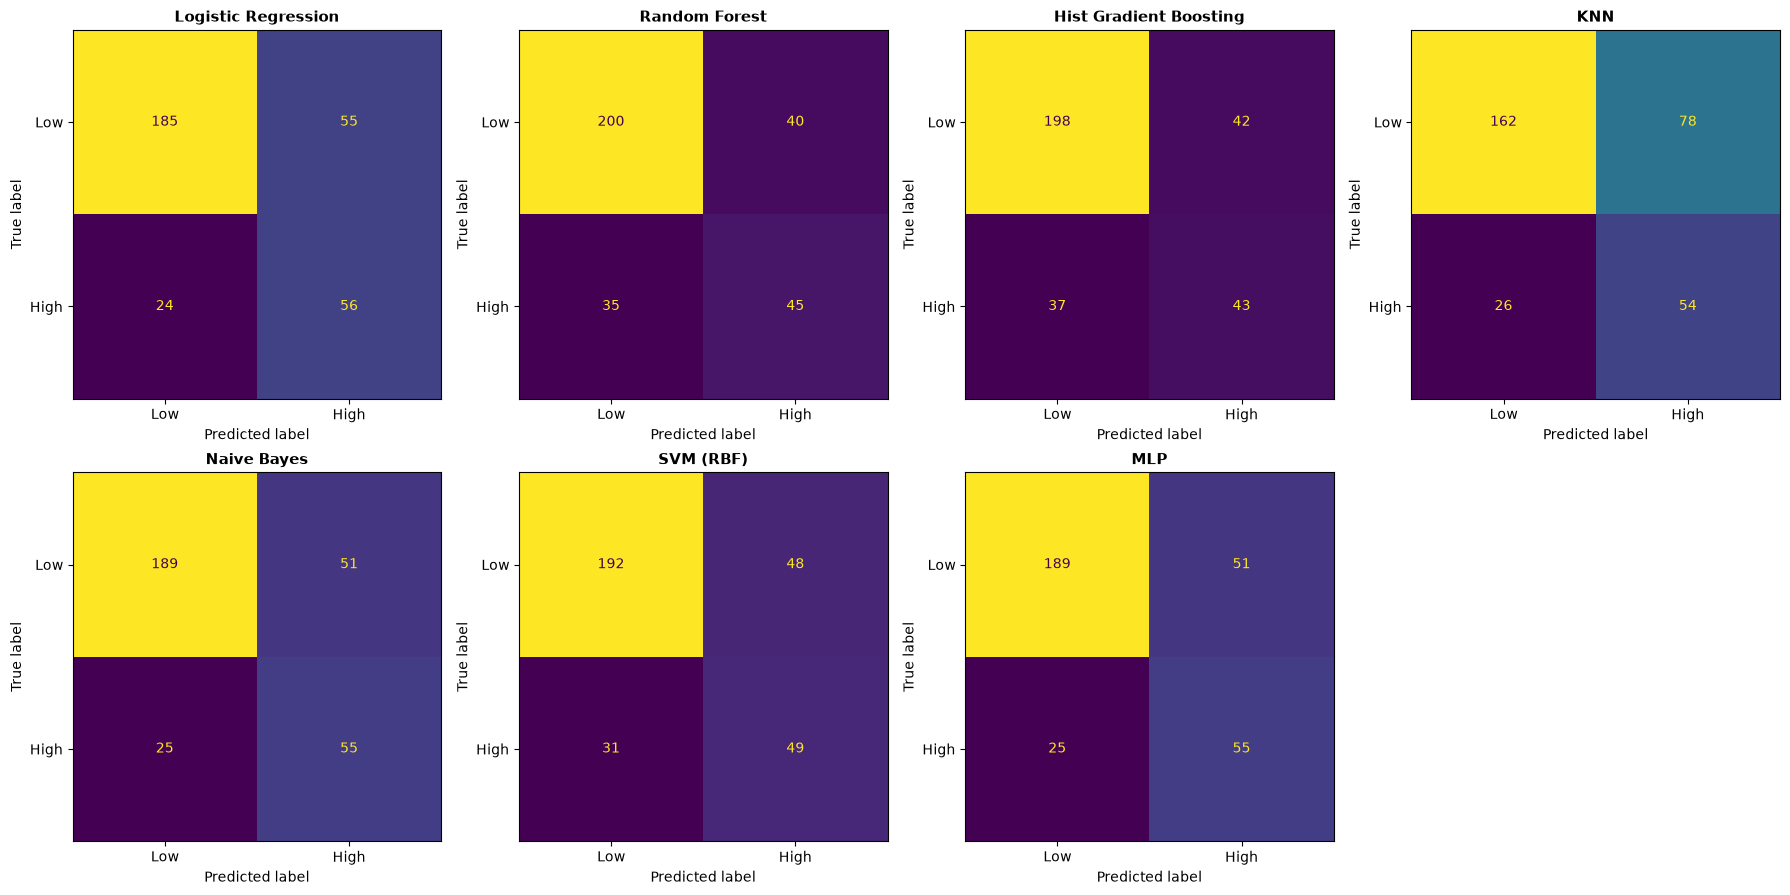

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()
for ax, (name, pipe) in zip(axes, best_estimators.items()):
    preds = pipe.predict(X_test)
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=['Low', 'High']).plot(ax=ax, colorbar=False)
    ax.set_title(name, fontsize=11, fontweight='bold')
for ax in axes[len(best_estimators):]:
    ax.axis('off')
plt.tight_layout()
plt.show()


**Draft notes: rewrite in your own words for the video:**

- Comparing all seven confusion matrices side by side (not just the winner's) shows the error *pattern*, not just the summary metric: e.g. which models lean toward over-predicting "High" (more false positives) versus under-predicting it (more false negatives).


#### Winner Deep-Dive: Learning Curve

In [19]:
winner_name = comparison_df.iloc[0]['Model']
winner_pipe = best_estimators[winner_name]

print(f"Winner (by 10-fold CV macro-F1): {winner_name}")
preds = winner_pipe.predict(X_test)
print(classification_report(y_test, preds, target_names=['Low', 'High']))


Winner (by 10-fold CV macro-F1): Logistic Regression
              precision    recall  f1-score   support

         Low       0.89      0.77      0.82       240
        High       0.50      0.70      0.59        80

    accuracy                           0.75       320
   macro avg       0.69      0.74      0.71       320
weighted avg       0.79      0.75      0.76       320



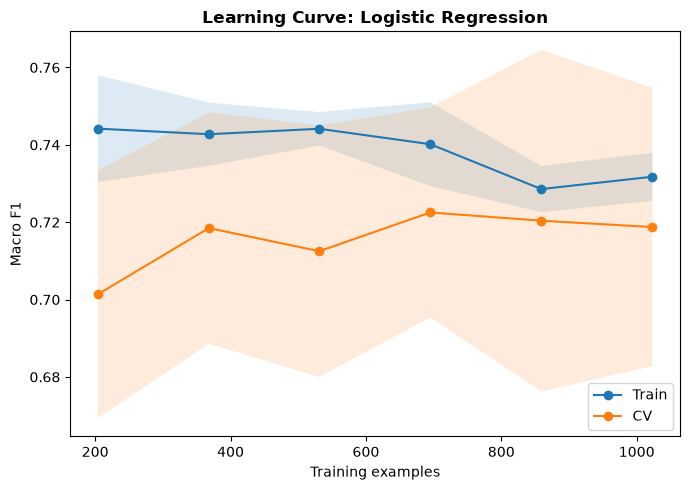

Final train=0.732, CV=0.719, gap=0.013


In [20]:
train_sizes, train_scores, val_scores = learning_curve(
    winner_pipe, X_train, y_train, cv=cv, scoring='f1_macro',
    train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1, shuffle=True, random_state=SEED,
)
train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
ax.plot(train_sizes, train_mean, 'o-', label='Train')
ax.plot(train_sizes, val_mean, 'o-', label='CV')
ax.set_xlabel('Training examples')
ax.set_ylabel('Macro F1')
ax.set_title(f'Learning Curve: {winner_name}', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Final train={train_mean[-1]:.3f}, CV={val_mean[-1]:.3f}, gap={train_mean[-1] - val_mean[-1]:.3f}")


**Draft notes: rewrite in your own words for the video:**

- If the train and CV lines converge as training set size increases (rather than staying far apart), that suggests the model isn't simply memorising: it's generalising, and more data would likely help further.
- If both lines plateau at a similar, middling score, that points to a ceiling driven by the *features* available rather than by model capacity: consistent with the Assignment 1 EDA finding that no single feature strongly predicts Fitness Level.


#### Beyond a Single Hold-Out: Optional Stability Check

**What already addresses the main feedback:** the official ranking above uses **10-fold cross-validation on the full dataset**. That is the scientifically required fix relative to reporting one 80/20 test score.

**What this section adds:** repeated random hold-out runs (here 100) to look at the *distribution* of scores and to run paired significance tests between models. Hyperparameters are **not** re-tuned inside every run. The configurations from `RandomizedSearchCV` are reused as fixed, so this step answers "how stable is each model's evaluation?", not "what are the best hyper-parameters?" (already answered above).

Treat these repeated runs as a stability / significance appendix. Model selection stays with the 10-fold CV table.


In [21]:
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score
from scipy import stats

def repeated_holdout(models_dict, X, y, n_runs, test_size=0.2, base_seed=0):
    """Run n_runs independent stratified train/test splits. The same split (same random_state)
    is used across every model within a given run, so results are paired and can be compared
    with a paired significance test."""
    records = {name: [] for name in models_dict}
    for run in range(n_runs):
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=test_size, stratify=y, random_state=base_seed + run
        )
        for name, pipe_template in models_dict.items():
            pipe = clone(pipe_template)
            pipe.fit(X_tr, y_tr)
            preds = pipe.predict(X_te)
            records[name].append({
                'run': run,
                'accuracy': accuracy_score(y_te, preds),
                'precision_macro': precision_score(y_te, preds, average='macro'),
                'recall_macro': recall_score(y_te, preds, average='macro'),
                'f1_macro': f1_score(y_te, preds, average='macro'),
            })
    return {name: pd.DataFrame(recs) for name, recs in records.items()}

def summarise_runs(results_dict):
    rows = []
    for name, df_res in results_dict.items():
        rows.append({
            'Model': name,
            'Mean F1': df_res['f1_macro'].mean(), 'Std F1': df_res['f1_macro'].std(),
            'Mean Accuracy': df_res['accuracy'].mean(), 'Std Accuracy': df_res['accuracy'].std(),
            'Mean Precision': df_res['precision_macro'].mean(), 'Mean Recall': df_res['recall_macro'].mean(),
        })
    return pd.DataFrame(rows).sort_values('Mean F1', ascending=False).reset_index(drop=True)


##### Repeated Hold-Out Runs (stability appendix)


In [22]:
# best_estimators already holds each model's tuned pipeline (fixed hyperparameters from RandomizedSearchCV)
results_100 = repeated_holdout(best_estimators, X, y, n_runs=100, base_seed=0)
summary_100 = summarise_runs(results_100).round(4)
summary_100


,Model,Mean F1,Std F1,Mean Accuracy,Std Accuracy,Mean Precision,Mean Recall
0,SVM (RBF),0.7180,0.0241,0.7721,0.0215,0.7084,0.7377
1,MLP,0.7145,0.0232,0.7655,0.0216,0.7047,0.7394
2,Logistic Regression,0.7126,0.0222,0.7539,0.0218,0.7036,0.7525
3,Naive Bayes,0.7040,0.0248,0.7514,0.0240,0.6947,0.7351
4,Random Forest,0.6938,0.0252,0.7620,0.0202,0.6890,0.7020
5,Hist Gradient Boosting,0.6920,0.0222,0.7616,0.0181,0.6879,0.6992
6,KNN,0.6734,0.0216,0.7086,0.0230,0.6746,0.7263


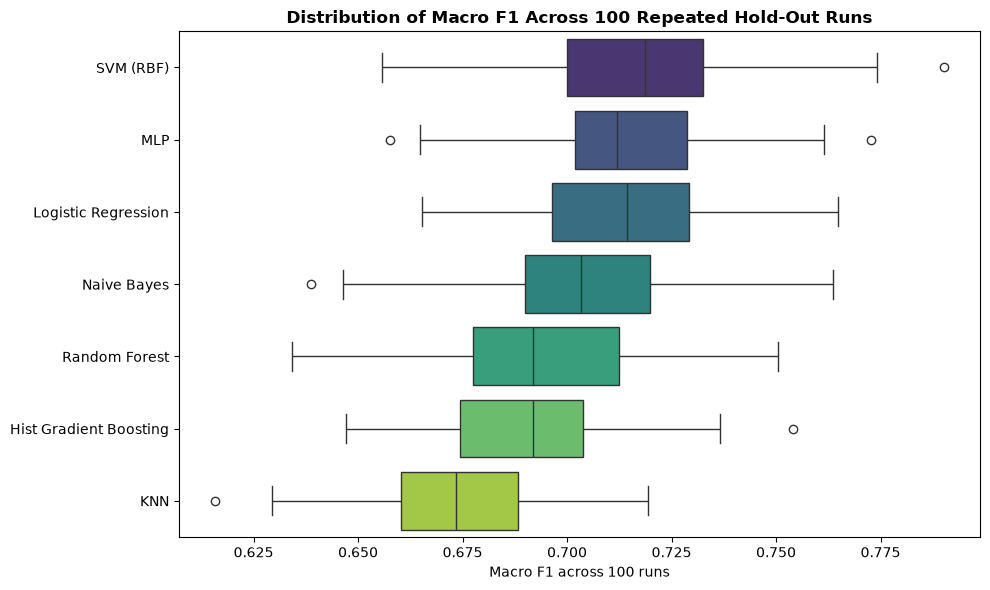

In [23]:
f1_data_100 = pd.DataFrame({name: res['f1_macro'] for name, res in results_100.items()})
order_100 = summary_100['Model'].tolist()

plt.figure(figsize=(10, 6))
sns.boxplot(data=f1_data_100[order_100], orient='h', palette='viridis')
plt.xlabel('Macro F1 across 100 runs')
plt.title('Distribution of Macro F1 Across 100 Repeated Hold-Out Runs', fontweight='bold')
plt.tight_layout()
plt.show()


**Draft notes: rewrite in your own words for the video**

- Compare this repeated-hold-out ranking to the official 10-fold CV table. Matching winners is a good stability sign; disagreement means keep the 10-fold winner as official and treat this section as variance context.
- The standard deviation column shows how stable each model's performance is: a model with a high mean but also a high std is less predictable than one with a similar mean and a tighter spread.
- The boxplot makes overlap between models visible directly: heavily overlapping boxes preview that a significance test between them is unlikely to find a real difference.


##### Statistical Significance Between Models

Since every model was evaluated on the *same* 100 splits, a **paired t-test** is appropriate: comparing each pair of models on their run-by-run differences, not just their means in isolation.


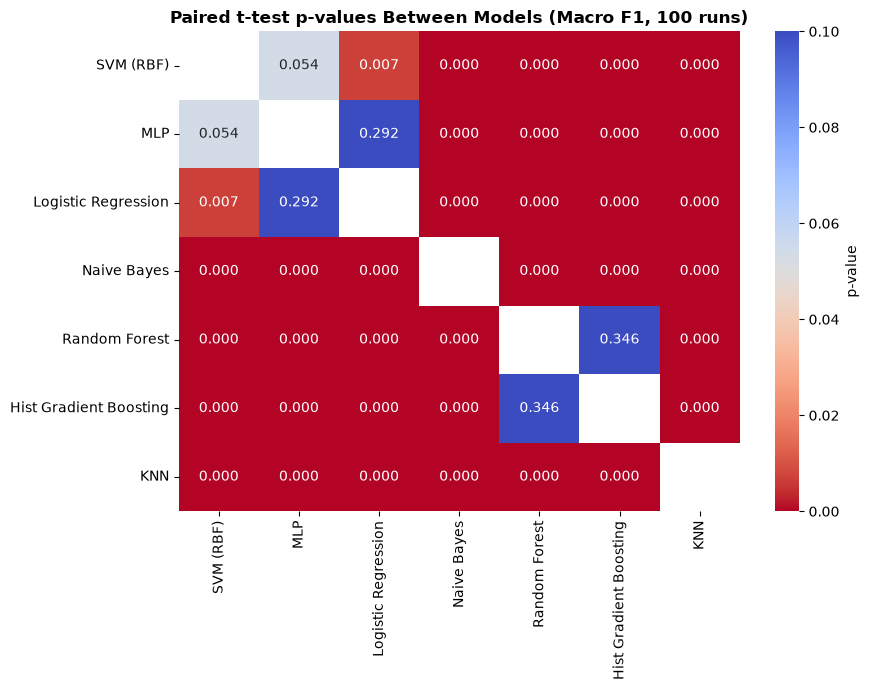

Number of pairwise comparisons: 21
Bonferroni-corrected significance threshold: 0.0024 (instead of the usual 0.05)


In [24]:
# Pairwise significance on the repeated hold-out appendix
model_names = summary_100['Model'].tolist()
pval_matrix = pd.DataFrame(index=model_names, columns=model_names, dtype=float)

for m1 in model_names:
    for m2 in model_names:
        if m1 == m2:
            pval_matrix.loc[m1, m2] = np.nan
        else:
            t_stat, p_val = stats.ttest_rel(results_100[m1]['f1_macro'], results_100[m2]['f1_macro'])
            pval_matrix.loc[m1, m2] = p_val

plt.figure(figsize=(9, 7))
sns.heatmap(pval_matrix.astype(float), annot=True, fmt='.3f', cmap='coolwarm_r', vmin=0, vmax=0.1,
            cbar_kws={'label': 'p-value'})
plt.title('Paired t-test p-values Between Models (Macro F1, 100 runs)', fontweight='bold')
plt.tight_layout()
plt.show()

n_comparisons = len(model_names) * (len(model_names) - 1) / 2
bonferroni_alpha = 0.05 / n_comparisons
print(f"Number of pairwise comparisons: {int(n_comparisons)}")
print(f"Bonferroni-corrected significance threshold: {bonferroni_alpha:.4f} (instead of the usual 0.05)")


**Draft notes: rewrite in your own words for the video**

- Cells with low p-values (darker on the heatmap) indicate pairs of models whose performance difference is unlikely to be due to chance alone.
- With 21 pairwise comparisons here, using the standard 0.05 threshold risks false positives just from running so many tests: the Bonferroni-corrected threshold above is stricter and more defensible when claiming any specific pair is "significantly different."
- If the top few models (by mean F1) don't show a significant pairwise difference, the honest conclusion is that this dataset's signal doesn't clearly separate them: worth saying explicitly rather than declaring a single "winner" with more confidence than the statistics support.

**A note on scope:** this notebook runs 100 repeated hold-out splits as a stability appendix. That is optional compute on top of the required 10-fold CV ranking. If time is short, 100 runs still illustrate variance; more runs only tighten the estimate.


## Task 2.3: Discussion of Results

This section covers: a results summary, a critical comparison of the seven models, error analysis, business/domain implications, and methodological limitations.


### Results Summary

The **primary** comparison is the **10-fold CV table** (`comparison_df`) from the implementation section. That is the official ranking. The repeated hold-out summary below is only a stability check: it shows how much scores move across many random splits, and supports paired tests, but it does not override the 10-fold winner.


In [25]:
print("Official ranking (10-fold CV on full data):")
print(comparison_df.to_string(index=False))
print("\nStability appendix (repeated hold-out summary):")
print(summary_100.to_string(index=False))


Official ranking (10-fold CV on full data):
                 Model  10-Fold CV macro-F1  10-Fold CV Accuracy  Full Train macro-F1  Gap (train - CV)
   Logistic Regression               0.7154               0.7561               0.7194            0.0040
             SVM (RBF)               0.7120               0.7648               0.7677            0.0557
                   MLP               0.7094               0.7605               0.8085            0.0991
           Naive Bayes               0.7024               0.7505               0.7065            0.0042
Hist Gradient Boosting               0.6978               0.7648               0.9003            0.2025
         Random Forest               0.6813               0.7492               0.7900            0.1088
                   KNN               0.6657               0.7004               1.0000            0.3343

Stability appendix (repeated hold-out summary):
                 Model  Mean F1  Std F1  Mean Accuracy  Std Accuracy  Mean 

**Draft notes: rewrite in your own words for the video**

- Lead with the 10-fold CV ranking: that is the mark the assignment asked for, and it uses every row of the cleaned data across stratified folds.
- Then, if useful, compare it to the repeated hold-out means. If the top model matches, say so. If not, treat that as sampling noise and keep the 10-fold winner as official.
- Standard deviation from the repeated runs still matters for stability: a model with a slightly lower mean but a tighter spread can be the more dependable practical choice.


### Critical Comparison: Which Model Is Best?

In [26]:
final_winner = comparison_df.iloc[0]['Model']
print(f"Official winner (10-fold CV macro-F1 on full data): {final_winner}")
print(
    f"10-Fold CV macro-F1: {comparison_df.iloc[0]['10-Fold CV macro-F1']:.4f} | "
    f"10-Fold CV Accuracy: {comparison_df.iloc[0]['10-Fold CV Accuracy']:.4f}"
)
print()
print("Closest rivals on 10-fold CV:")
comparison_df.iloc[1:3]


Official winner (10-fold CV macro-F1 on full data): Logistic Regression
10-Fold CV macro-F1: 0.7154 | 10-Fold CV Accuracy: 0.7561

Closest rivals on 10-fold CV:


,Model,10-Fold CV macro-F1,10-Fold CV Accuracy,Full Train macro-F1,Gap (train - CV)
1,SVM (RBF),0.7120,0.7648,0.7677,0.0557
2,MLP,0.7094,0.7605,0.8085,0.0991


**Draft notes: rewrite in your own words for the video**

- This winner comes from **10-fold CV on the full dataset**, which is the evaluation method requested in feedback. Check the gap to the next rows in `comparison_df` before overselling a "clear" win.
- The repeated hold-out paired tests remain useful context: if the top two models are not separable there either, say honestly that the dataset signal is weak and the ranking is close.
- The narrow margins between top models still reflect the Assignment 1 finding that no feature correlates strongly with Fitness Level (roughly ±0.24 at best). That is a data ceiling, not proof that the modelling process failed.


### What's Driving the Predictions?

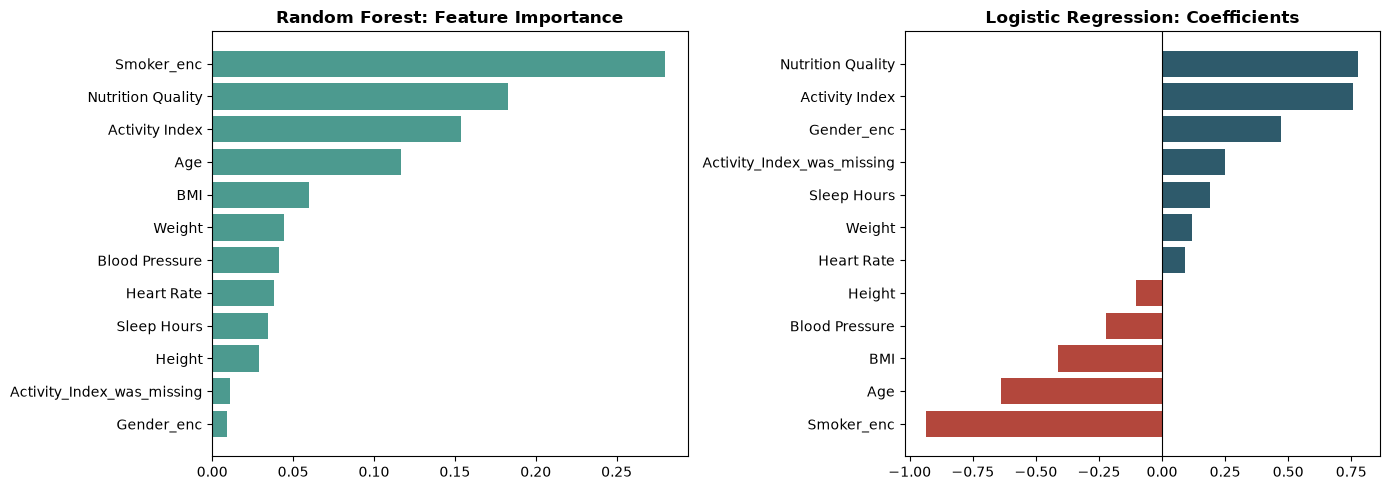

In [27]:
# Compare feature importance (Random Forest) against coefficients (Logistic Regression),
# regardless of which model won overall: both give a view on what the data is telling every model.
rf_pipe = best_estimators['Random Forest']
logreg_pipe = best_estimators['Logistic Regression']

importances = rf_pipe.named_steps['clf'].feature_importances_
imp_df = pd.DataFrame({'feature': feature_cols, 'importance': importances}).sort_values('importance', ascending=False)

coefs = logreg_pipe.named_steps['clf'].coef_[0]
coef_df = pd.DataFrame({'feature': feature_cols, 'coefficient': coefs}).sort_values('coefficient', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(imp_df['feature'], imp_df['importance'], color='#4C9A8F')
axes[0].set_title('Random Forest: Feature Importance', fontweight='bold')
axes[0].invert_yaxis()

colors = ['#B3473C' if v < 0 else '#2E5A6B' for v in coef_df['coefficient']]
axes[1].barh(coef_df['feature'], coef_df['coefficient'], color=colors)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Logistic Regression: Coefficients', fontweight='bold')
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()


**Draft notes: rewrite in your own words for the video:**

- Both models agree that **Nutrition Quality and Activity Index are the strongest predictors**: consistent with the correlations found in the Assignment 1 EDA (+0.24 and +0.23 respectively). Worth stating this explicitly: the modelling results corroborate the earlier EDA rather than contradicting it.
- **Smoker status is surprisingly influential in both models**: worth connecting back to the counter-intuitive EDA finding that smokers had *higher* average Nutrition Quality scores. A univariate relationship (smoking vs nutrition) doesn't have to match the multivariate one (smoking vs fitness once everything else is accounted for): a good example of why relying on individual correlations alone can mislead.


### Error Analysis: Where and Why Did the Model Fail?

In [28]:
X_test_labelled = X_test.copy()
X_test_labelled['actual'] = y_test.values
X_test_labelled['predicted'] = winner_pipe.predict(X_test)

false_negatives = X_test_labelled[(X_test_labelled['actual'] == 1) & (X_test_labelled['predicted'] == 0)]
true_positives = X_test_labelled[(X_test_labelled['actual'] == 1) & (X_test_labelled['predicted'] == 1)]

error_comparison = pd.DataFrame({
    'False Negatives (missed "High")': false_negatives[feature_cols].mean(),
    'True Positives (correctly caught)': true_positives[feature_cols].mean(),
}).round(2)
error_comparison['Difference'] = (
    error_comparison['False Negatives (missed "High")']
    - error_comparison['True Positives (correctly caught)']
).round(2)
error_comparison.sort_values('Difference', key=abs, ascending=False)


,"False Negatives (missed ""High"")",True Positives (correctly caught),Difference
Age,57.79,44.16,13.63
Nutrition Quality,3.57,6.85,-3.28
Height,174.88,177.07,-2.19
Weight,81.54,79.59,1.95
BMI,27.18,25.61,1.57
Heart Rate,70.21,68.78,1.43
Activity Index,2.74,3.44,-0.70
Sleep Hours,7.19,7.70,-0.51
Smoker_enc,0.50,0.18,0.32
Blood Pressure,119.22,119.44,-0.22


**Draft notes: rewrite in your own words for the video:**

- Compare the genuinely "High" fitness people the winning model **missed** against the ones it **correctly caught**: look for which features differ most between the two groups.
- If (as found in an earlier version of this analysis) the missed cases have notably lower Nutrition Quality and a higher smoker rate than the correctly-caught cases, that indicates the model's errors aren't random: they concentrate on people who are genuinely fit but whose overall profile statistically resembles a typical "Low" fitness person. That's a substantive, model-specific finding, not a generic "the model isn't perfect" statement.


### Business / Domain Implications

**Draft notes: rewrite in your own words for the video:**

- Even with seven models, broader tuning, and SMOTE, macro-F1 tops out in the low-to-mid 0.70s: reinforcing what the Assignment 1 EDA already suggested: no individual feature strongly predicts Fitness Level, and clustering showed weak natural separability between the two classes. This performance ceiling looks driven by the data available, not by insufficient modelling effort.
- For a real deployment (e.g. a wellness app flagging users for a fitness programme), this means predictions should support human judgement rather than replace it: especially given the error analysis shows the model is least reliable on exactly the interesting edge cases (e.g. fit smokers with poor nutrition scores) a business might most want to catch.
- The choice between the top few close models in practice would come down to which type of error costs more in that specific business context: missing a genuinely fit person, or wrongly flagging someone who isn't.


### Methodological Limitations and Recommended Improvements

**Draft notes: rewrite in your own words for the video**

- **Dataset size and class imbalance**: ~1,600 rows with a 75/25 split leaves relatively few genuine "High" examples (~320) even before any oversampling. SMOTE helps the training process see a balanced signal, but it synthesises new points rather than collecting new genuine data. A real increase in labelled "High" examples would likely help more than any modelling change.
- **Imputation risk carried forward from Assignment 1**: Activity Index was ~51% imputed, and it remains one of the strongest predictors across models, so a meaningful share of the model's reliance sits on estimated, not observed, values.
- **Search scope**: `RandomizedSearchCV` with up to 12 draws per model is reasonable but not exhaustive, particularly for larger grids (Random Forest, Hist Gradient Boosting, MLP). A wider search or more iterations could be explored with more compute time.
- **Hold-out plots are diagnostic only**: confusion matrices and the learning curve still use one 80/20 split for visualisation. Official ranking is the 10-fold CV table, so those plots should not be read as a second leaderboard.
- **Recommended next step**: given the error analysis finding, a worthwhile follow-up would be testing whether adding an interaction term (for example Smoker × Nutrition Quality) helps the model better capture cases where the two features point in different directions.


## AI Declaration and Reflection

### AI Tools Declaration

I used ChatGPT (GPT-4o) and GitHub Copilot during the development of this assignment. These tools were used as programming assistants to help debug Python errors, look up scikit-learn syntax (for example `RandomizedSearchCV`, `cross_validate`, and pipeline wiring with SMOTE), and tidy matplotlib / seaborn plot formatting. They were not used to invent the modelling story or to write the scientific conclusions unsupervised.

### AI Tools Reflection and Lessons Learnt

Using GenAI for dataframe formatting and plot boilerplate saved time. Early on it was less reliable on methodology: when asked how to handle class imbalance it sometimes suggested dropping minority rows, which would have damaged the dataset. The useful pattern was to decide the workflow myself first (SMOTE only inside CV folds, macro-F1 as the ranking metric, 10-fold CV on the full data for final comparison) and only then ask AI for syntax help implementing that design.

### AI Academic Integrity

All methodological decisions, model selections, justifications, and critical analyses in this notebook are my own work. GenAI was limited to syntax support, debugging, and formatting. I checked every generated snippet against the assignment requirements and against the EDA findings from Assignment 1 before keeping it.
